# Model evaluation and tuning

Evaluate a balanced logistic classifier with stratified cross-validation and tune regularization strength.

**Dataset:** `data/student_data.csv` (395 student records, 33 columns). **Target:** final grade `G3` (0–20). For classification labs, pass means `G3 ≥ 10`. Earlier grades `G1` and `G2` are included as predictors; interpret results as prediction after those earlier grades are known. The split is fixed with random seed 42 for reproducibility.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATHS = [Path("data/student_data.csv"), Path("../data/student_data.csv")]
DATA_PATH = next((p for p in DATA_PATHS if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Place student_data.csv in the repository's data/ folder.")
df = pd.read_csv(DATA_PATH)
TARGET = "G3"  # final-period grade (0–20)
PASS_THRESHOLD = 10
numeric_features = df.select_dtypes(include=np.number).columns.drop(TARGET).tolist()
categorical_features = df.select_dtypes(exclude=np.number).columns.tolist()
feature_cols = numeric_features + categorical_features
X = df[feature_cols]
y_reg = df[TARGET]
y_class = (df[TARGET] >= PASS_THRESHOLD).astype(int)


In [2]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

def make_preprocessor(scale_numeric=True):
    numeric_steps = [("scale", StandardScaler())] if scale_numeric else []
    numeric_pipe = Pipeline(numeric_steps) if numeric_steps else "passthrough"
    return ColumnTransformer(
        [("numeric", numeric_pipe, numeric_features),
         ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features)],
        remainder="drop",
    )


,mean,std
accuracy,0.908814,0.050199
f1_macro,0.896964,0.056864
roc_auc,0.970447,0.017933


Best parameters: {'classifier__C': 1}
Best mean CV macro F1: 0.897
                 precision    recall  f1-score   support

Below threshold       0.75      0.91      0.82        33
           Pass       0.95      0.85      0.90        66

       accuracy                           0.87        99
      macro avg       0.85      0.88      0.86        99
   weighted avg       0.88      0.87      0.87        99



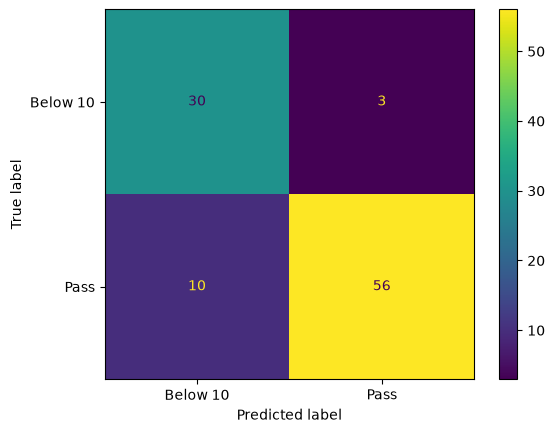

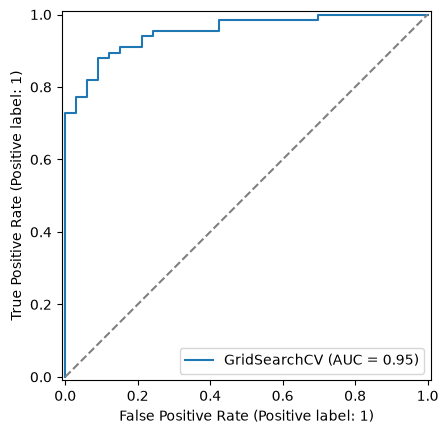

In [3]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, RocCurveDisplay

X_train, X_test, y_train, y_test = train_test_split(X, y_class, test_size=0.25, stratify=y_class, random_state=42)
pipe=Pipeline([("preprocess",make_preprocessor()),("classifier",LogisticRegression(max_iter=2000,class_weight="balanced"))])
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
scores=cross_validate(pipe,X_train,y_train,cv=cv,scoring=["accuracy","f1_macro","roc_auc"])
display(pd.DataFrame({k.replace("test_",""):v for k,v in scores.items() if k.startswith("test_")}).agg(["mean","std"]).T)
search=GridSearchCV(pipe,{"classifier__C":[0.01,0.1,1,10,100]},cv=cv,scoring="f1_macro",n_jobs=-1)
search.fit(X_train,y_train)
print("Best parameters:",search.best_params_)
print("Best mean CV macro F1:",round(search.best_score_,3))
pred=search.predict(X_test)
print(classification_report(y_test,pred,target_names=["Below threshold","Pass"],zero_division=0))
ConfusionMatrixDisplay.from_estimator(search,X_test,y_test,display_labels=["Below 10","Pass"]); plt.show()
RocCurveDisplay.from_estimator(search,X_test,y_test); plt.plot([0,1],[0,1],"--",color="gray"); plt.show()
